# Многослойная полносвязная сеть
В этом упражнении вы реализуете полносвязную сеть с произвольным числом скрытых слоёв.

In [1]:
# Настройка окружения (запустите эту ячейку первой).
# Откройте ноутбук из папки python/ задания, например: uv run jupyter lab
# При первом запуске скачается CIFAR-10 (~170 МБ): с сервера курса, а если он
# недоступен, с официального сайта. Источник можно задать явно переменной
# окружения DLCV_DATASET_SOURCE=racoon или official перед запуском Jupyter.
import os
import sys

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки python/ задания.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from dlcv.data_utils import ensure_cifar10
ensure_cifar10()
print('Рабочая папка:', os.getcwd())
import numpy as np
np.random.seed(231)


Рабочая папка: C:\Users\yar04\OneDrive\Документы\ChatGPT\MISIS\deep-learning\assignment1


Изучите класс `FullyConnectedNet` в файле `dlcv/classifiers/fc_net.py`.

Реализуйте инициализацию сети, прямой и обратный проходы. Все слои в этой лабораторной работе реализуются в файле `dlcv/layers.py`. Можно повторно использовать уже написанные вами реализации `affine_forward`, `affine_backward`, `relu_forward`, `relu_backward` и `softmax_loss`.


In [2]:
# Подготовительная ячейка.
import time
import numpy as np
import matplotlib.pyplot as plt
from dlcv.classifiers.fc_net import *
from dlcv.data_utils import get_CIFAR10_data
from dlcv.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from dlcv.solver import Solver

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0)  # Размер графиков по умолчанию.
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """Возвращает относительную ошибку."""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

In [3]:
# Загружаем (предобработанные) данные CIFAR-10.
data = get_CIFAR10_data()
for k, v in list(data.items()):
    print(f"{k}: {v.shape}")

X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


## Начальное значение потерь и проверка градиента

В качестве быстрой проверки запустите ячейку ниже: она вычислит начальное значение функции потерь и выполнит проверку градиента (gradient check) для сети как с регуляризацией, так и без неё. Это хороший способ убедиться, что начальные значения потерь выглядят разумно.

При проверке градиента ошибки должны быть порядка 1e-7 или меньше (при `reg = 0` для `W2` допустима ошибка порядка 1e-5).

In [4]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
    print("Проверка при reg = ", reg)
    model = FullyConnectedNet(
        [H1, H2],
        input_dim=D,
        num_classes=C,
        reg=reg,
        weight_scale=5e-2,
        dtype=np.float64
    )

    loss, grads = model.loss(X, y)
    print("Начальные потери: ", loss)

    # Большинство ошибок должно быть порядка 1e-7 или меньше.
    # ПРИМЕЧАНИЕ: при проверке с reg = 0.0 ошибка для W2 порядка 1e-5
    # тоже допустима.
    for name in sorted(grads):
        f = lambda _: model.loss(X, y)[0]
        grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
        print(f"{name} — относительная ошибка: {rel_error(grad_num, grads[name])}")

Проверка при reg =  0
Начальные потери:  2.3004790897684924
W1 — относительная ошибка: 1.4839894098713283e-07


W2 — относительная ошибка: 2.21204793107852e-05


W3 — относительная ошибка: 3.527252851540647e-07
b1 — относительная ошибка: 5.376386228531692e-09
b2 — относительная ошибка: 2.085654200257447e-09
b3 — относительная ошибка: 5.7957243458479405e-11
Проверка при reg =  3.14
Начальные потери:  7.052114776533016
W1 — относительная ошибка: 3.904541941902138e-09


W2 — относительная ошибка: 6.86942277940646e-08


W3 — относительная ошибка: 2.131129848945024e-08
b1 — относительная ошибка: 1.4752427965311745e-08
b2 — относительная ошибка: 1.7223751746766738e-09
b3 — относительная ошибка: 1.5702714832602802e-10


Ещё одна быстрая проверка: убедитесь, что ваша сеть способна переобучиться на маленьком наборе данных из 50 изображений. Сначала попробуем трёхслойную сеть со 100 нейронами в каждом скрытом слое. В следующей ячейке подберите **скорость обучения (learning rate)** и **масштаб инициализации весов** так, чтобы сеть переобучилась и за 20 эпох достигла 100% точности (accuracy, доля правильных ответов) на обучающей выборке.

(Итерация 1 / 40) потери: 31.521642
(Эпоха 0 / 20) точность на обучении: 0.260000; на валидации: 0.101000
(Эпоха 1 / 20) точность на обучении: 0.220000; на валидации: 0.128000


(Эпоха 2 / 20) точность на обучении: 0.520000; на валидации: 0.112000
(Эпоха 3 / 20) точность на обучении: 0.620000; на валидации: 0.112000
(Эпоха 4 / 20) точность на обучении: 0.800000; на валидации: 0.118000


(Эпоха 5 / 20) точность на обучении: 0.820000; на валидации: 0.123000
(Итерация 11 / 40) потери: 0.154281
(Эпоха 6 / 20) точность на обучении: 0.760000; на валидации: 0.120000


(Эпоха 7 / 20) точность на обучении: 0.940000; на валидации: 0.120000
(Эпоха 8 / 20) точность на обучении: 0.980000; на валидации: 0.128000


(Эпоха 9 / 20) точность на обучении: 1.000000; на валидации: 0.124000
(Эпоха 10 / 20) точность на обучении: 1.000000; на валидации: 0.124000
(Итерация 21 / 40) потери: 0.011654
(Эпоха 11 / 20) точность на обучении: 1.000000; на валидации: 0.123000


(Эпоха 12 / 20) точность на обучении: 1.000000; на валидации: 0.122000
(Эпоха 13 / 20) точность на обучении: 1.000000; на валидации: 0.122000


(Эпоха 14 / 20) точность на обучении: 1.000000; на валидации: 0.124000
(Эпоха 15 / 20) точность на обучении: 1.000000; на валидации: 0.123000
(Итерация 31 / 40) потери: 0.002796


(Эпоха 16 / 20) точность на обучении: 1.000000; на валидации: 0.123000
(Эпоха 17 / 20) точность на обучении: 1.000000; на валидации: 0.124000
(Эпоха 18 / 20) точность на обучении: 1.000000; на валидации: 0.125000


(Эпоха 19 / 20) точность на обучении: 1.000000; на валидации: 0.125000
(Эпоха 20 / 20) точность на обучении: 1.000000; на валидации: 0.125000


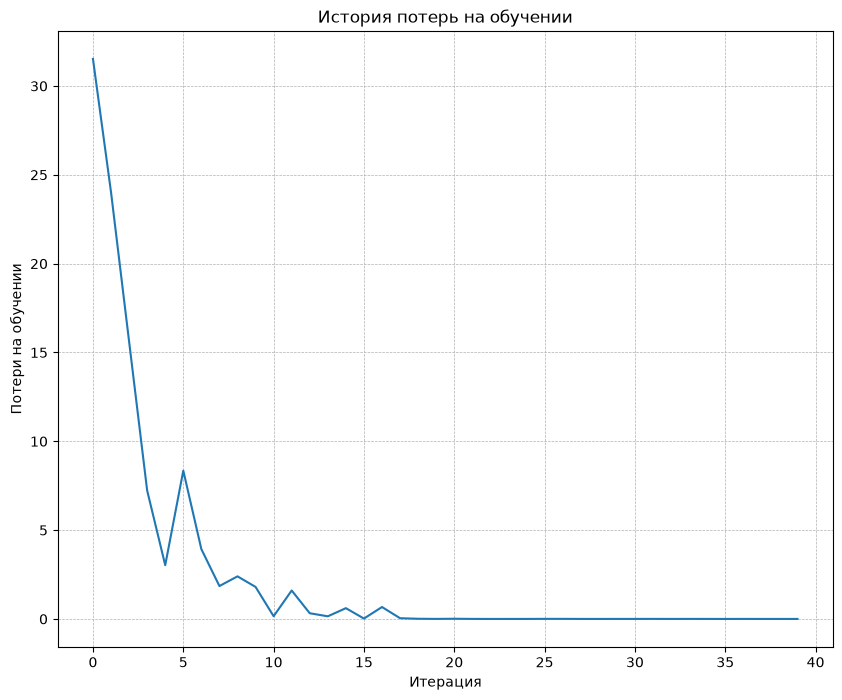

In [5]:
# Решение: Добейтесь переобучения трёхслойной сети на 50 обучающих примерах,
# изменяя только скорость обучения и масштаб инициализации.

num_train = 50
small_data = {
  "X_train": data["X_train"][:num_train],
  "y_train": data["y_train"][:num_train],
  "X_val": data["X_val"],
  "y_val": data["y_val"],
}

np.random.seed(231)
weight_scale = 0.05   # Поэкспериментируйте с этим значением!
learning_rate = 1e-3  # Поэкспериментируйте с этим значением!


model = FullyConnectedNet(
    [100, 100],
    weight_scale=weight_scale,
    dtype=np.float64
)
solver = Solver(
    model,
    small_data,
    print_every=10,
    num_epochs=20,
    batch_size=25,
    update_rule="sgd",
    optim_config={"learning_rate": learning_rate},
)
solver.train()

plt.plot(solver.loss_history)
plt.title("История потерь на обучении")
plt.xlabel("Итерация")
plt.ylabel("Потери на обучении")
plt.grid(linestyle='--', linewidth=0.5)
plt.show()
assert max(solver.train_acc_history) == 1.0, solver.train_acc_history


Теперь попробуйте добиться переобучения на 50 обучающих примерах с помощью пятислойной сети со 100 нейронами в каждом слое. Вам снова придётся подбирать скорость обучения и масштаб инициализации весов, но и здесь должно получиться достичь 100% точности на обучающей выборке за 20 эпох.

(Итерация 1 / 40) потери: 155.087589
(Эпоха 0 / 20) точность на обучении: 0.200000; на валидации: 0.088000
(Эпоха 1 / 20) точность на обучении: 0.180000; на валидации: 0.111000
(Эпоха 2 / 20) точность на обучении: 0.360000; на валидации: 0.140000
(Эпоха 3 / 20) точность на обучении: 0.600000; на валидации: 0.124000
(Эпоха 4 / 20) точность на обучении: 0.860000; на валидации: 0.141000
(Эпоха 5 / 20) точность на обучении: 0.860000; на валидации: 0.141000
(Итерация 11 / 40) потери: 0.356270
(Эпоха 6 / 20) точность на обучении: 0.940000; на валидации: 0.131000


(Эпоха 7 / 20) точность на обучении: 0.940000; на валидации: 0.137000
(Эпоха 8 / 20) точность на обучении: 0.960000; на валидации: 0.139000
(Эпоха 9 / 20) точность на обучении: 1.000000; на валидации: 0.137000
(Эпоха 10 / 20) точность на обучении: 1.000000; на валидации: 0.129000
(Итерация 21 / 40) потери: 0.000190
(Эпоха 11 / 20) точность на обучении: 1.000000; на валидации: 0.129000
(Эпоха 12 / 20) точность на обучении: 1.000000; на валидации: 0.129000
(Эпоха 13 / 20) точность на обучении: 1.000000; на валидации: 0.129000


(Эпоха 14 / 20) точность на обучении: 1.000000; на валидации: 0.129000
(Эпоха 15 / 20) точность на обучении: 1.000000; на валидации: 0.129000
(Итерация 31 / 40) потери: 0.000995
(Эпоха 16 / 20) точность на обучении: 1.000000; на валидации: 0.129000
(Эпоха 17 / 20) точность на обучении: 1.000000; на валидации: 0.130000
(Эпоха 18 / 20) точность на обучении: 1.000000; на валидации: 0.130000
(Эпоха 19 / 20) точность на обучении: 1.000000; на валидации: 0.130000
(Эпоха 20 / 20) точность на обучении: 1.000000; на валидации: 0.129000


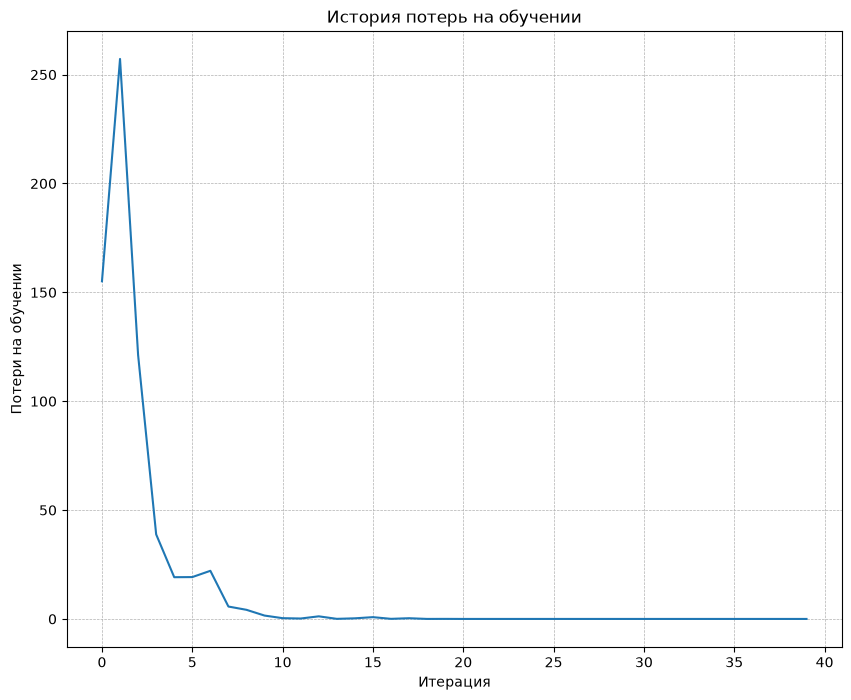

In [6]:
# Решение: Добейтесь переобучения пятислойной сети на 50 обучающих примерах,
# изменяя только скорость обучения и масштаб инициализации.

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

np.random.seed(231)
learning_rate = 1e-3  # Поэкспериментируйте с этим значением!
weight_scale = 0.1   # Поэкспериментируйте с этим значением!


model = FullyConnectedNet(
    [100, 100, 100, 100],
    weight_scale=weight_scale,
    dtype=np.float64
)
solver = Solver(
    model,
    small_data,
    print_every=10,
    num_epochs=20,
    batch_size=25,
    update_rule='sgd',
    optim_config={'learning_rate': learning_rate},
)
solver.train()

plt.plot(solver.loss_history)
plt.title('История потерь на обучении')
plt.xlabel('Итерация')
plt.ylabel('Потери на обучении')
plt.grid(linestyle='--', linewidth=0.5)
plt.show()
assert max(solver.train_acc_history) == 1.0, solver.train_acc_history


## Вопрос 1
Заметили ли вы разницу в том, насколько сложно обучать трёхслойную и пятислойную сети? В частности, какая из двух сетей, судя по вашему опыту, оказалась более чувствительной к масштабу инициализации весов? Как вы думаете, почему так происходит?

**Ваш ответ:** Пятислойная сеть чувствительнее к масштабу инициализации. При обратном проходе градиент многократно умножается на матрицы весов и маски ReLU: слишком малые веса гасят сигнал, слишком большие могут вызвать взрыв активаций и градиентов. В более глубокой сети эффект накапливается сильнее. Параметры выше подобраны на маленькой обучающей выборке; достижение 100% проверяется явно.


# Правила обновления параметров
До сих пор в качестве правила обновления мы использовали обычный (vanilla) стохастический градиентный спуск (SGD). Более совершенные правила обновления могут облегчить обучение глубоких сетей. Реализуем несколько самых распространённых правил обновления и сравним их с обычным SGD.

## SGD с моментом (SGD+Momentum)
Стохастический градиентный спуск с моментом (momentum) — широко используемое правило обновления, с которым глубокие сети, как правило, сходятся быстрее, чем с обычным SGD. Помимо весов $w$, метод хранит «скорость» (velocity) $v$ — накопленное направление движения; в коде это массив `config["velocity"]`, изначально нулевой. На каждом шаге выполняется обновление

$$v \leftarrow \mu v - \alpha \nabla_w L, \qquad w \leftarrow w + v,$$

где $\mu$ — коэффициент момента (`config["momentum"]`, по умолчанию 0.9), $\alpha$ — скорость обучения (`config["learning_rate"]`), а $\nabla_w L$ — градиент функции потерь по $w$ (аргумент `dw`).

Откройте файл `dlcv/optim.py` и прочитайте документацию в начале файла, чтобы разобраться в общем интерфейсе (API) правил обновления. Реализуйте правило SGD с моментом в функции `sgd_momentum` и запустите ячейку ниже, чтобы проверить реализацию. Относительные ошибки должны быть порядка 1e-8 или меньше.

In [7]:
from dlcv.optim import sgd_momentum

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {"learning_rate": 1e-3, "velocity": v}
next_w, _ = sgd_momentum(w, dw, config=config)

expected_next_w = np.asarray([
  [ 0.1406,      0.20738947,  0.27417895,  0.34096842,  0.40775789],
  [ 0.47454737,  0.54133684,  0.60812632,  0.67491579,  0.74170526],
  [ 0.80849474,  0.87528421,  0.94207368,  1.00886316,  1.07565263],
  [ 1.14244211,  1.20923158,  1.27602105,  1.34281053,  1.4096    ]])
expected_velocity = np.asarray([
  [ 0.5406,      0.55475789,  0.56891579, 0.58307368,  0.59723158],
  [ 0.61138947,  0.62554737,  0.63970526,  0.65386316,  0.66802105],
  [ 0.68217895,  0.69633684,  0.71049474,  0.72465263,  0.73881053],
  [ 0.75296842,  0.76712632,  0.78128421,  0.79544211,  0.8096    ]])

# Относительные ошибки должны быть порядка 1e-8 или меньше.
print("ошибка next_w: ", rel_error(next_w, expected_next_w))
print("ошибка velocity: ", rel_error(expected_velocity, config["velocity"]))

ошибка next_w:  8.882347033505819e-09
ошибка velocity:  4.269287743278663e-09


Когда реализация будет готова, запустите ячейку ниже, чтобы обучить шестислойную сеть с помощью обычного SGD и SGD с моментом. Вы должны увидеть, что SGD с моментом сходится быстрее.

Обучение с правилом  sgd
(Итерация 1 / 200) потери: 2.534428
(Эпоха 0 / 5) точность на обучении: 0.083000; на валидации: 0.095000
(Итерация 11 / 200) потери: 2.272551


(Итерация 21 / 200) потери: 2.099137
(Итерация 31 / 200) потери: 2.174980
(Эпоха 1 / 5) точность на обучении: 0.249000; на валидации: 0.233000
(Итерация 41 / 200) потери: 2.063420


(Итерация 51 / 200) потери: 2.092000
(Итерация 61 / 200) потери: 2.026439
(Итерация 71 / 200) потери: 2.004612
(Эпоха 2 / 5) точность на обучении: 0.311000; на валидации: 0.261000


(Итерация 81 / 200) потери: 1.983295
(Итерация 91 / 200) потери: 1.969099
(Итерация 101 / 200) потери: 1.964826
(Итерация 111 / 200) потери: 2.013370


(Эпоха 3 / 5) точность на обучении: 0.328000; на валидации: 0.284000
(Итерация 121 / 200) потери: 1.795479
(Итерация 131 / 200) потери: 1.923870
(Итерация 141 / 200) потери: 1.818773
(Итерация 151 / 200) потери: 1.840951


...

(Итерация 61 / 200) потери: 1.900373
(Итерация 71 / 200) потери: 1.756109
(Эпоха 2 / 5) точность на обучении: 0.382000; на валидации: 0.340000
(Итерация 81 / 200) потери: 1.588975


(Итерация 91 / 200) потери: 1.540493
(Итерация 101 / 200) потери: 1.562081
(Итерация 111 / 200) потери: 1.821298


(Эпоха 3 / 5) точность на обучении: 0.479000; на валидации: 0.355000
(Итерация 121 / 200) потери: 1.307125
(Итерация 131 / 200) потери: 1.585566
(Итерация 141 / 200) потери: 1.378856


(Итерация 151 / 200) потери: 1.486194
(Эпоха 4 / 5) точность на обучении: 0.518000; на валидации: 0.371000
(Итерация 161 / 200) потери: 1.470350
(Итерация 171 / 200) потери: 1.365234


(Итерация 181 / 200) потери: 1.521069
(Итерация 191 / 200) потери: 1.367778
(Эпоха 5 / 5) точность на обучении: 0.542000; на валидации: 0.369000


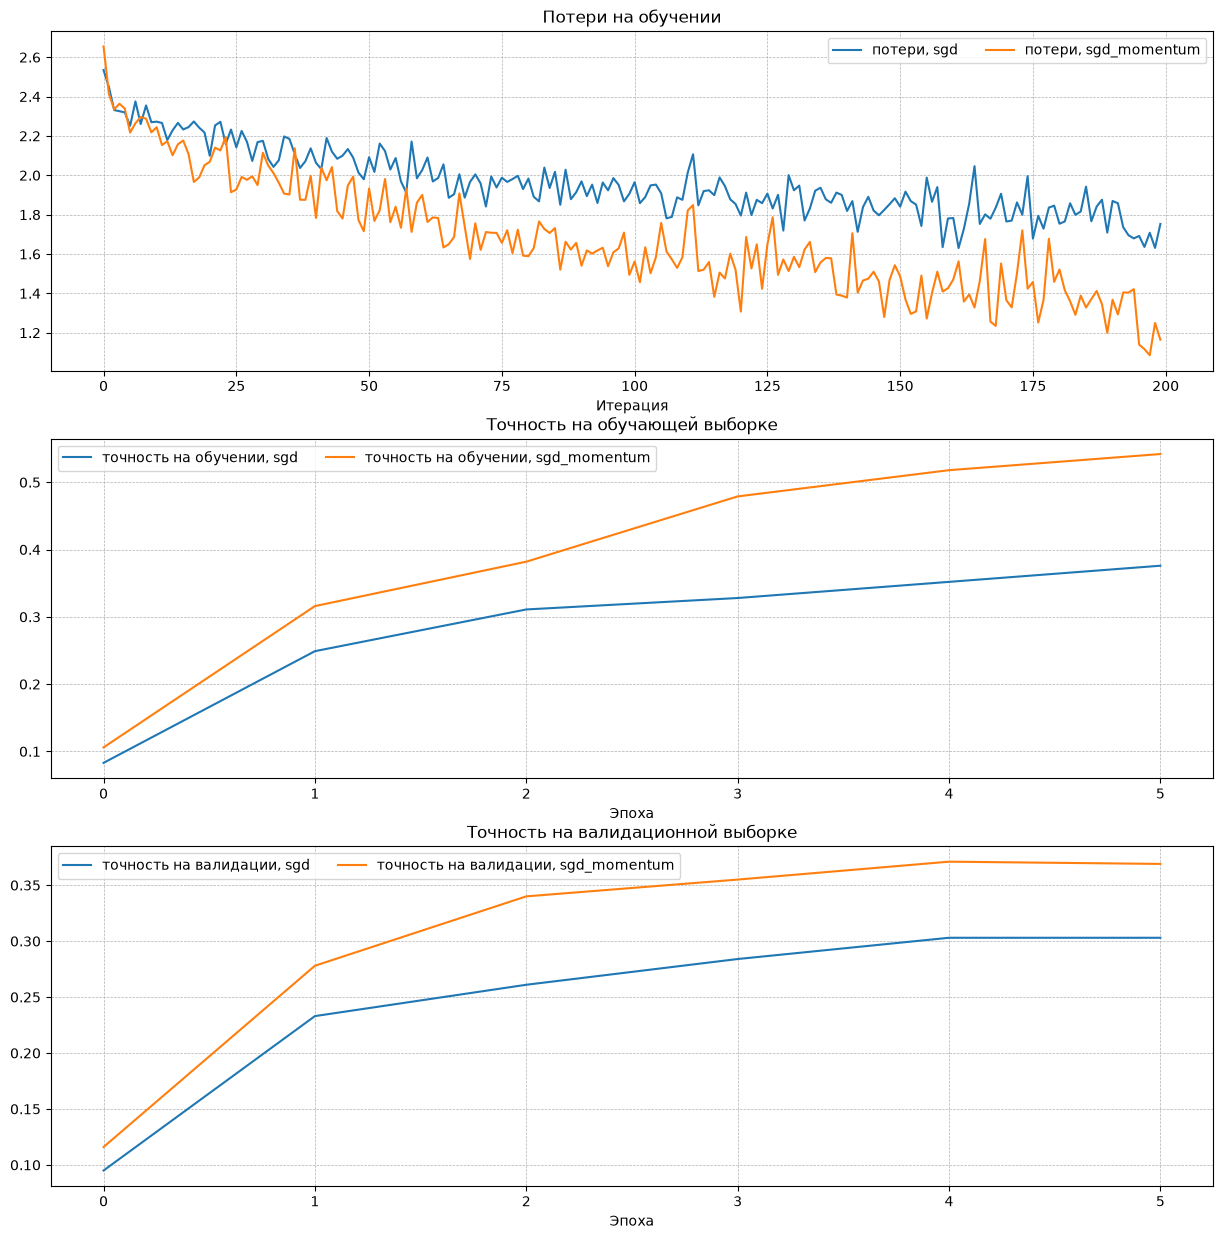

In [8]:
num_train = 4000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}

for update_rule in ['sgd', 'sgd_momentum']:
    print('Обучение с правилом ', update_rule)
    model = FullyConnectedNet(
        [100, 100, 100, 100, 100],
        weight_scale=5e-2
    )

    solver = Solver(
        model,
        small_data,
        num_epochs=5,
        batch_size=100,
        update_rule=update_rule,
        optim_config={'learning_rate': 5e-3},
        verbose=True,
    )
    solvers[update_rule] = solver
    solver.train()

fig, axes = plt.subplots(3, 1, figsize=(15, 15))

axes[0].set_title('Потери на обучении')
axes[0].set_xlabel('Итерация')
axes[1].set_title('Точность на обучающей выборке')
axes[1].set_xlabel('Эпоха')
axes[2].set_title('Точность на валидационной выборке')
axes[2].set_xlabel('Эпоха')

for update_rule, solver in solvers.items():
    axes[0].plot(solver.loss_history, label=f"потери, {update_rule}")
    axes[1].plot(solver.train_acc_history, label=f"точность на обучении, {update_rule}")
    axes[2].plot(solver.val_acc_history, label=f"точность на валидации, {update_rule}")

for ax in axes:
    ax.legend(loc="best", ncol=4)
    ax.grid(linestyle='--', linewidth=0.5)

plt.show()

## RMSProp и Adam
RMSProp [1] и Adam [2] — правила обновления, которые подбирают собственную скорость обучения для каждого параметра, используя скользящее среднее вторых моментов градиентов.

В файле `dlcv/optim.py` реализуйте правило RMSProp в функции `rmsprop` и правило Adam в функции `adam`, а затем проверьте свои реализации с помощью тестов ниже.

Обозначения: $\nabla_w L$ — градиент функции потерь по весам (аргумент `dw`), $\alpha$ — скорость обучения (`config["learning_rate"]`), $\varepsilon$ — малая константа, защищающая от деления на ноль (`config["epsilon"]`). Возведение в квадрат, корень и деление выполняются поэлементно.

**RMSProp.** Здесь $\rho$ — коэффициент затухания (`config["decay_rate"]`), $c$ — скользящее среднее квадратов градиента (`config["cache"]`):

$$c \leftarrow \rho c + (1-\rho)(\nabla_w L)^2, \qquad w \leftarrow w - \alpha \nabla_w L / (\sqrt{c} + \varepsilon).$$

**Adam.** Здесь $\beta_1$, $\beta_2$ — коэффициенты затухания для первого и второго моментов (`config["beta1"]`, `config["beta2"]`), $m$ и $v$ — скользящие средние градиента и его квадрата (`config["m"]`, `config["v"]`), $t$ — номер итерации (`config["t"]`):

$$t \leftarrow t + 1;$$

$$m \leftarrow \beta_1 m + (1-\beta_1) \nabla_w L, \qquad v \leftarrow \beta_2 v + (1-\beta_2)(\nabla_w L)^2;$$

$$\hat m = m / (1-\beta_1^t), \qquad \hat v = v / (1-\beta_2^t);$$

$$w \leftarrow w - \alpha \hat m / (\sqrt{\hat v} + \varepsilon).$$

**Примечание:** реализуйте _полную_ версию правила Adam — с коррекцией смещения ($\hat m$, $\hat v$). Счётчик $t$ нужно увеличить _до_ того, как использовать его в вычислениях, иначе результат не совпадёт с эталонным.

[1] Tijmen Tieleman and Geoffrey Hinton. "Lecture 6.5-rmsprop: Divide the gradient by a running average of its recent magnitude." COURSERA: Neural Networks for Machine Learning 4 (2012).

[2] Diederik Kingma and Jimmy Ba, "Adam: A Method for Stochastic Optimization", ICLR 2015.

In [9]:
# Проверка реализации RMSProp
from dlcv.optim import rmsprop

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
cache = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'cache': cache}
next_w, _ = rmsprop(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.39223849, -0.34037513, -0.28849239, -0.23659121, -0.18467247],
  [-0.132737,   -0.08078555, -0.02881884,  0.02316247,  0.07515774],
  [ 0.12716641,  0.17918792,  0.23122175,  0.28326742,  0.33532447],
  [ 0.38739248,  0.43947102,  0.49155973,  0.54365823,  0.59576619]])
expected_cache = np.asarray([
  [ 0.5976,      0.6126277,   0.6277108,   0.64284931,  0.65804321],
  [ 0.67329252,  0.68859723,  0.70395734,  0.71937285,  0.73484377],
  [ 0.75037008,  0.7659518,   0.78158892,  0.79728144,  0.81302936],
  [ 0.82883269,  0.84469141,  0.86060554,  0.87657507,  0.8926    ]])

# Относительные ошибки должны быть порядка 1e-7 или меньше (значения чуть
# больше 1e-7 — норма: эталонные массивы округлены до 8 знаков).
print('ошибка next_w: ', rel_error(expected_next_w, next_w))
print('ошибка cache: ', rel_error(expected_cache, config['cache']))

ошибка next_w:  9.524687511038133e-08
ошибка cache:  2.6477955807156126e-09


In [10]:
# Проверка реализации Adam
from dlcv.optim import adam

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
m = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
v = np.linspace(0.7, 0.5, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'm': m, 'v': v, 't': 5}
next_w, _ = adam(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.40094747, -0.34836187, -0.29577703, -0.24319299, -0.19060977],
  [-0.1380274,  -0.08544591, -0.03286534,  0.01971428,  0.0722929],
  [ 0.1248705,   0.17744702,  0.23002243,  0.28259667,  0.33516969],
  [ 0.38774145,  0.44031188,  0.49288093,  0.54544852,  0.59801459]])
expected_v = np.asarray([
  [ 0.69966,     0.68908382,  0.67851319,  0.66794809,  0.65738853,],
  [ 0.64683452,  0.63628604,  0.6257431,   0.61520571,  0.60467385,],
  [ 0.59414753,  0.58362676,  0.57311152,  0.56260183,  0.55209767,],
  [ 0.54159906,  0.53110598,  0.52061845,  0.51013645,  0.49966,   ]])
expected_m = np.asarray([
  [ 0.48,        0.49947368,  0.51894737,  0.53842105,  0.55789474],
  [ 0.57736842,  0.59684211,  0.61631579,  0.63578947,  0.65526316],
  [ 0.67473684,  0.69421053,  0.71368421,  0.73315789,  0.75263158],
  [ 0.77210526,  0.79157895,  0.81105263,  0.83052632,  0.85      ]])

# Относительные ошибки должны быть порядка 1e-7 или меньше (значения чуть
# больше 1e-7 — норма: эталонные массивы округлены до 8 знаков).
print('ошибка next_w: ', rel_error(expected_next_w, next_w))
print('ошибка v: ', rel_error(expected_v, config['v']))
print('ошибка m: ', rel_error(expected_m, config['m']))

ошибка next_w:  1.1395691798535431e-07
ошибка v:  4.208314038113071e-09
ошибка m:  4.214963193114416e-09


Когда отладите реализации RMSProp и Adam, запустите ячейку ниже, чтобы обучить две глубокие сети с этими новыми правилами обновления:

Обучение с правилом  adam
(Итерация 1 / 200) потери: 2.481510
(Эпоха 0 / 5) точность на обучении: 0.111000; на валидации: 0.114000


(Итерация 11 / 200) потери: 2.108005


(Итерация 21 / 200) потери: 2.055475


(Итерация 31 / 200) потери: 1.892280


(Эпоха 1 / 5) точность на обучении: 0.319000; на валидации: 0.310000
(Итерация 41 / 200) потери: 1.912645


...

(Итерация 81 / 200) потери: 1.633509
(Итерация 91 / 200) потери: 1.484280
(Итерация 101 / 200) потери: 1.645543


(Итерация 111 / 200) потери: 1.701947
(Эпоха 3 / 5) точность на обучении: 0.463000; на валидации: 0.351000
(Итерация 121 / 200) потери: 1.529704


(Итерация 131 / 200) потери: 1.602751
(Итерация 141 / 200) потери: 1.533722
(Итерация 151 / 200) потери: 1.418465


(Эпоха 4 / 5) точность на обучении: 0.499000; на валидации: 0.359000
(Итерация 161 / 200) потери: 1.359579
(Итерация 171 / 200) потери: 1.385015
(Итерация 181 / 200) потери: 1.342333


(Итерация 191 / 200) потери: 1.380417
(Эпоха 5 / 5) точность на обучении: 0.497000; на валидации: 0.367000



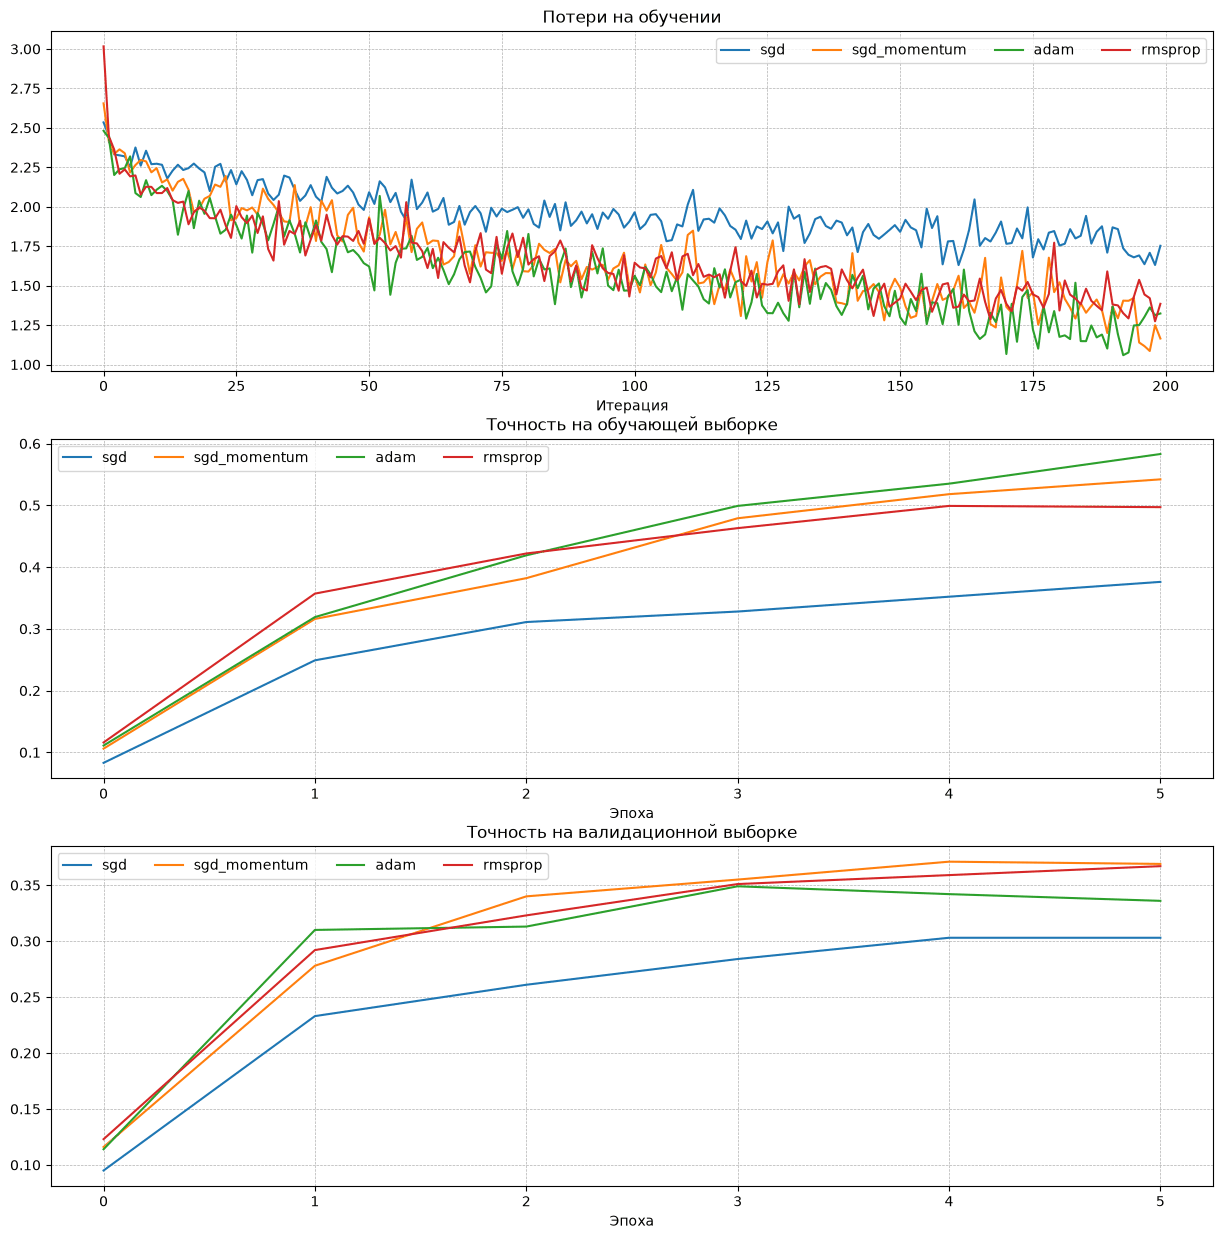

In [11]:
learning_rates = {'rmsprop': 1e-4, 'adam': 1e-3}
for update_rule in ['adam', 'rmsprop']:
    print('Обучение с правилом ', update_rule)
    model = FullyConnectedNet(
        [100, 100, 100, 100, 100],
        weight_scale=5e-2
    )
    solver = Solver(
        model,
        small_data,
        num_epochs=5,
        batch_size=100,
        update_rule=update_rule,
        optim_config={'learning_rate': learning_rates[update_rule]},
        verbose=True
    )
    solvers[update_rule] = solver
    solver.train()
    print()

fig, axes = plt.subplots(3, 1, figsize=(15, 15))

axes[0].set_title('Потери на обучении')
axes[0].set_xlabel('Итерация')
axes[1].set_title('Точность на обучающей выборке')
axes[1].set_xlabel('Эпоха')
axes[2].set_title('Точность на валидационной выборке')
axes[2].set_xlabel('Эпоха')

for update_rule, solver in solvers.items():
    axes[0].plot(solver.loss_history, label=f"{update_rule}")
    axes[1].plot(solver.train_acc_history, label=f"{update_rule}")
    axes[2].plot(solver.val_acc_history, label=f"{update_rule}")

for ax in axes:
    ax.legend(loc='best', ncol=4)
    ax.grid(linestyle='--', linewidth=0.5)

plt.show()

## Вопрос 2

AdaGrad, как и Adam, — метод оптимизации с отдельной скоростью обучения для каждого параметра. Он использует следующее правило обновления:

```
cache += dw**2
w += - learning_rate * dw / (np.sqrt(cache) + eps)
```

Студент заметил, что при обучении сети с помощью AdaGrad обновления становились очень маленькими и сеть обучалась медленно. Опираясь на то, как устроено правило обновления AdaGrad, объясните, почему обновления могут становиться очень маленькими. Возникнет ли такая же проблема у Adam?

**Ваш ответ:** В AdaGrad cache — сумма всех прошлых квадратов градиента. Она не убывает, поэтому знаменатель растёт, а эффективный шаг постепенно уменьшается. Adam использует экспоненциально затухающие средние, а не бесконечную сумму: старые градиенты забываются, поэтому такого неизбежного накопительного затухания нет. Однако маленькие обновления возможны и у Adam, например при малом learning rate или слабом текущем первом моменте.


# Обучите хорошую модель!
Обучите на CIFAR-10 лучшую полносвязную модель, какую сможете, и сохраните её в переменной `best_model`. Требуется, чтобы полносвязная сеть достигала точности не менее 50% на валидационной выборке.

При аккуратном подборе гиперпараметров можно получить точность выше 55%, но это не обязательно. Для изображений гораздо лучше подходят свёрточные сети, поэтому тратить здесь слишком много времени не нужно.

**Примечание:** обучать более мощные модели помогают такие приёмы, как батч-нормализация (batch normalization) и прореживание (dropout); в этой лабораторной работе они не требуются.

In [12]:
best_model = None

################################################################################
# Решение: Обучите на CIFAR-10 лучшую модель FullyConnectedNet, какую сможете.    #
# Сохраните лучшую модель в переменной best_model.                             #
################################################################################



################################################################################
#                              КОНЕЦ ВАШЕГО КОДА                               #
################################################################################
best_val = -1
for dims, lr, reg in [([200, 100], 5e-4, 0.01), ([200, 100], 1e-3, 0.05)]:
    candidate = FullyConnectedNet(dims, weight_scale=0.02, reg=reg)
    candidate_solver = Solver(candidate, data, update_rule='adam',
                              optim_config={'learning_rate': lr}, lr_decay=0.95,
                              num_epochs=15, batch_size=200, print_every=500)
    candidate_solver.train()
    val = candidate_solver.check_accuracy(data['X_val'], data['y_val'])
    print('dims, lr, reg:', dims, lr, reg, 'validation:', val)
    if val > best_val:
        best_val, best_model = val, candidate
assert best_val >= 0.5, best_val
best_model.save('best_fully_connected_net.npy')


(Итерация 1 / 3675) потери: 4.495918
(Эпоха 0 / 15) точность на обучении: 0.199000; на валидации: 0.190000


(Эпоха 1 / 15) точность на обучении: 0.493000; на валидации: 0.458000


(Эпоха 2 / 15) точность на обучении: 0.491000; на валидации: 0.475000


(Итерация 501 / 3675) потери: 1.933632


(Эпоха 3 / 15) точность на обучении: 0.545000; на валидации: 0.487000


...

(Итерация 3001 / 3675) потери: 1.538693


(Эпоха 13 / 15) точность на обучении: 0.517000; на валидации: 0.468000


(Эпоха 14 / 15) точность на обучении: 0.527000; на валидации: 0.477000


(Итерация 3501 / 3675) потери: 1.704303


(Эпоха 15 / 15) точность на обучении: 0.495000; на валидации: 0.481000
dims, lr, reg: [200, 100] 0.001 0.05 validation: 0.481
best_fully_connected_net.npy сохранён.


# Проверьте свою модель!
Оцените лучшую модель на валидационной и тестовой выборках. Точность на валидационной выборке должна быть не ниже 50%; на тестовой выборке она должна получиться примерно такой же.

In [13]:
y_test_pred = np.argmax(best_model.loss(data['X_test']), axis=1)
y_val_pred = np.argmax(best_model.loss(data['X_val']), axis=1)
print('Точность на валидационной выборке: ', (y_val_pred == data['y_val']).mean())
print('Точность на тестовой выборке: ', (y_test_pred == data['y_test']).mean())

Точность на валидационной выборке:  0.526
Точность на тестовой выборке:  0.539
